In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

SEED = 987

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df = listings.copy()

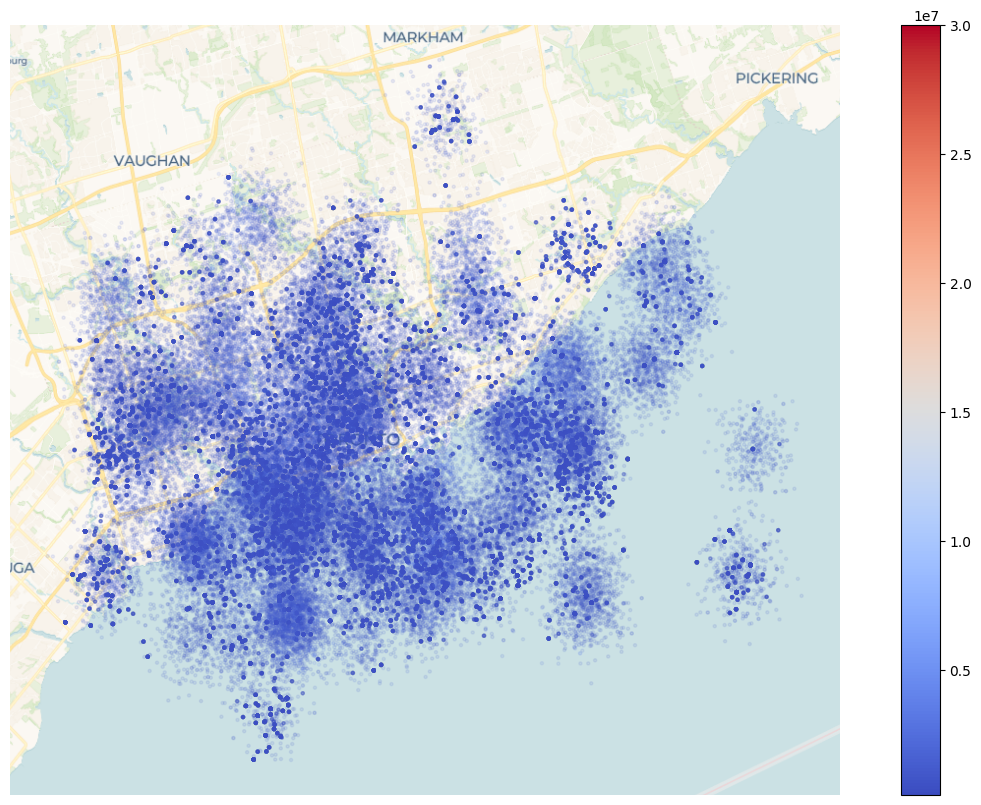

In [ ]:
import geopandas as gpd
import contextily as cx

carto_positron_url = "https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png?key=DO_NOT_LEAK_API_KEYS"

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
    crs="EPSG:4326"
).to_crs(epsg=3857)

ax = gdf.plot(figsize=(16, 10), markersize=5, alpha=0.1, column="sold_price", cmap="coolwarm", legend=True)
cx.add_basemap(ax, source=carto_positron_url)
ax.set_axis_off()
plt.show()

- wowzers it appears that houses at the edges of groups are more expensive than those in the centre

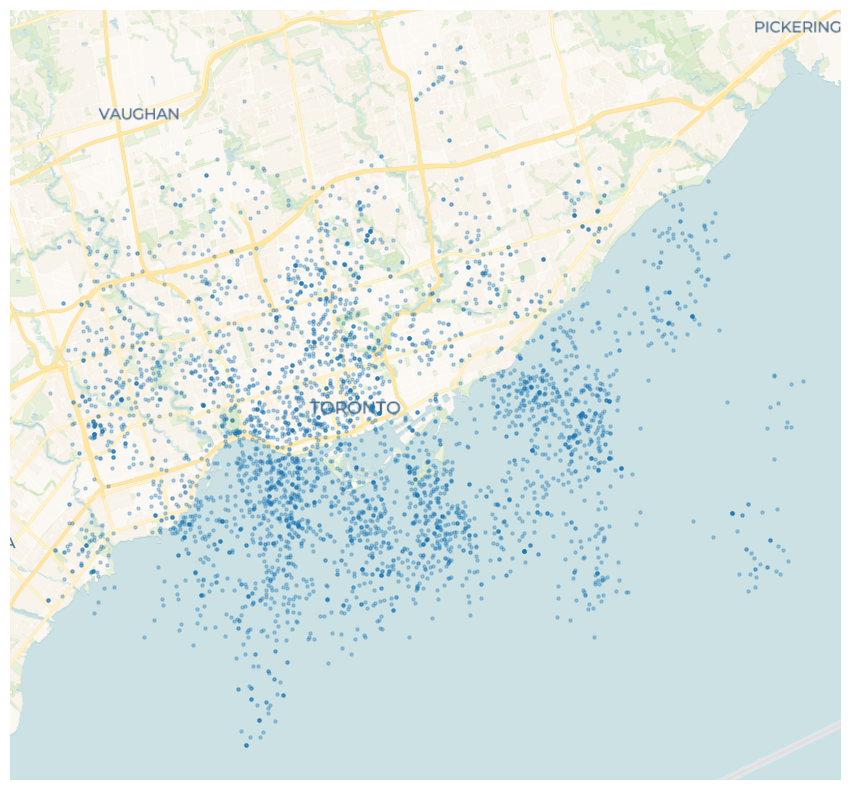

In [5]:
gdf = gpd.GeoDataFrame(
    off_market,
    geometry=gpd.points_from_xy(off_market["longitude"], off_market["latitude"]),
    crs="EPSG:4326"
).to_crs(epsg=3857)

ax = gdf.plot(figsize=(16, 10), markersize=5, alpha=0.3)
cx.add_basemap(ax, source=carto_positron_url)
ax.set_axis_off()
plt.show()

In [6]:
df["municipality"].unique()

array(['Toronto', 'North York', 'Scarborough', 'Etobicoke', 'York'],
      dtype=object)

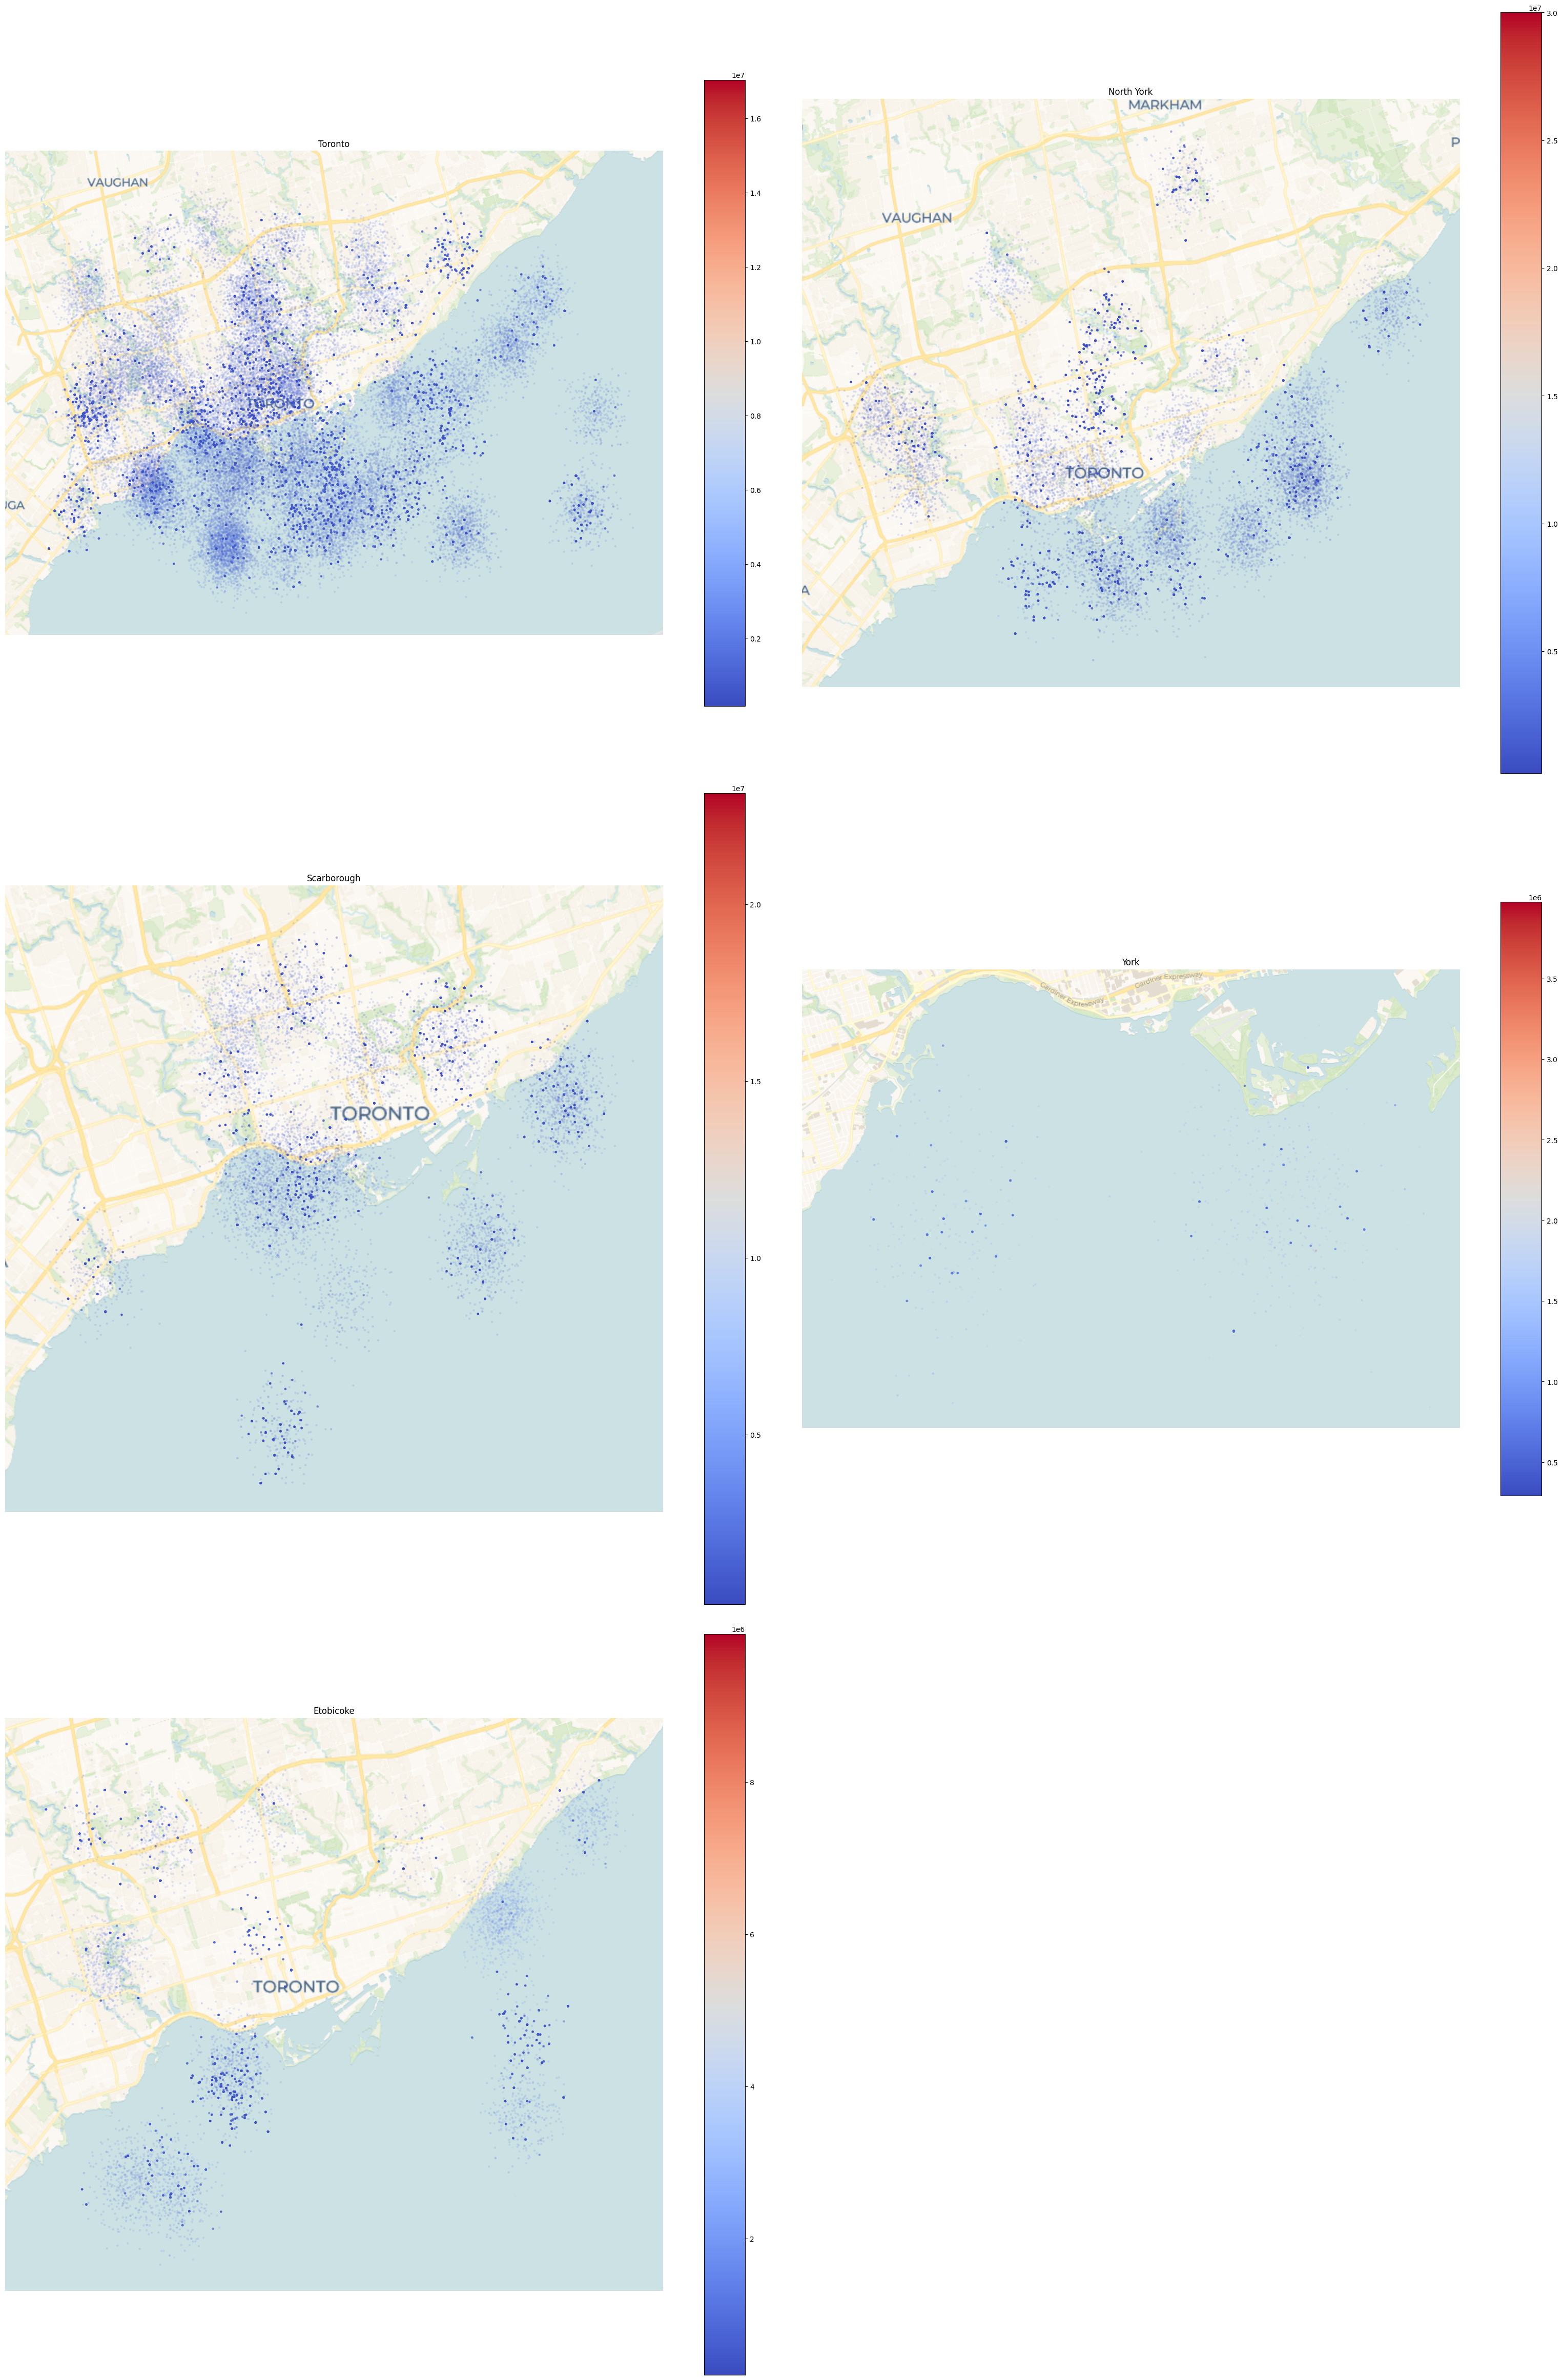

In [9]:
# By municipality
fig, axes = plt.subplots(3, 2, figsize=(32, 48))
axes = axes.flatten()

toronto_houses = df[df["municipality"] == "Toronto"]
north_york_houses = df[df["municipality"] == "North York"]
scarborough_houses = df[df["municipality"] == "Scarborough"]
york_houses = df[df["municipality"] == "York"]
etobicoke_houses = df[df["municipality"] == "Etobicoke"]

for i, house_df in enumerate([toronto_houses, north_york_houses, scarborough_houses, york_houses, etobicoke_houses]):
    gdf = gpd.GeoDataFrame(
        house_df,
        geometry=gpd.points_from_xy(house_df["longitude"], house_df["latitude"]),
        crs="EPSG:4326"
    ).to_crs(epsg=3857)

    ax = gdf.plot(ax=axes[i], markersize=5, alpha=0.1, column="sold_price", cmap="coolwarm", legend=True)
    cx.add_basemap(ax, source=carto_positron_url)
    ax.set_title(house_df["municipality"].iloc[0])
    ax.set_axis_off()
plt.tight_layout()
axes[-1].set_visible(False)
plt.show()

- my goodness there is so much overlap between municipalities what is this???

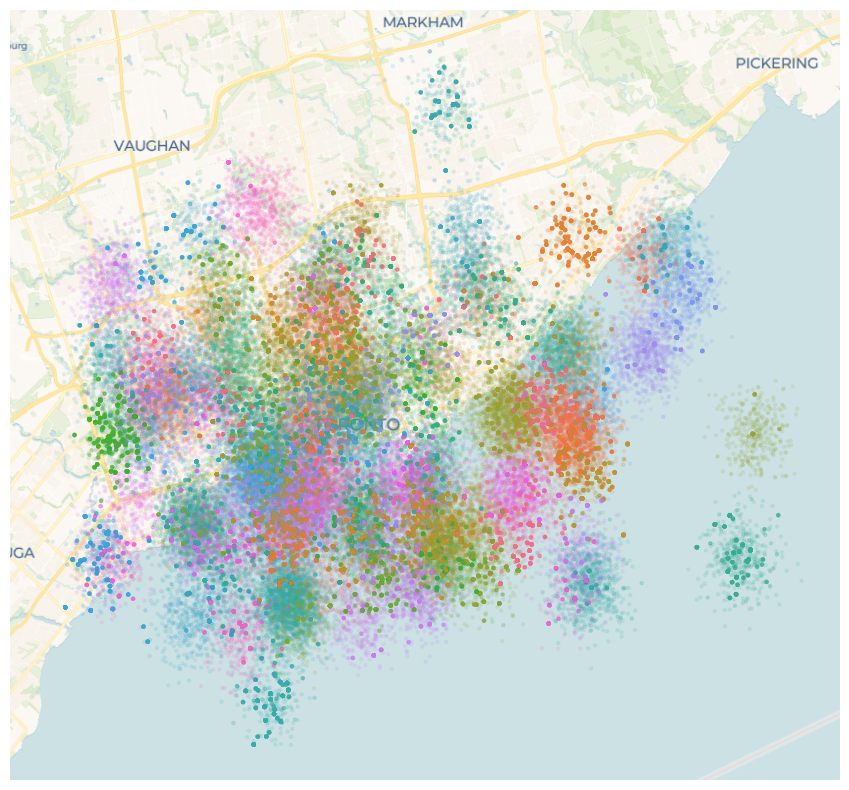

In [18]:
# Looking at area of various communities
categories = df["community"].unique()
palette = sns.color_palette("husl", n_colors=len(categories))
color_map = dict(zip(categories, palette))

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
    crs="EPSG:4326"
).to_crs(epsg=3857)

ax = gdf.plot(figsize=(16, 10), markersize=5, alpha=0.1, column="community", color=df["community"].map(color_map), legend=False)
cx.add_basemap(ax, source=carto_positron_url)
# handles, labels = ax.get_legend_handles_labels()
# ax.legend(title="Community", loc="upper left", bbox_to_anchor=(1.02, 1))
# ax.legend(handles[:20], labels[:20], title="Community", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_axis_off()
plt.show()